In [1]:
# Based on the following works:

# Hernández, Q., Badías, A., González, D., Chinesta, F., & Cueto, E. (2021).
# Structure-preserving neural networks.
# Journal of Computational Physics, 426, 109950.
# https://doi.org/10.1016/j.jcp.2020.109950

# QuercusHernandez. (2021). StructurePreservingNN [GitHub repository].
# Retrieved January 26, 2026, from https://github.com/quercushernandez/StructurePreservingNN

In [2]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()))))
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()), 'model')))
sys.path.append(os.path.abspath(os.path.join(os.path.dirname(os.getcwd()), '../../src')))

In [3]:
import torch
import numpy as np 
import scipy

# TensOps library
import tensopsciml as to
from tensopsciml.tensors import TensOps

from model.architecture import SPNN
from trainers.train import train_model
from utils.plots import plot_system_grid
from utils.split_datasets import split_dataset

torch.manual_seed(123)
np.random.seed(123)

In [4]:
# Load .mat file and check variables
data = scipy.io.loadmat(os.path.join('..', 'dataset', 'database_double_pendulum.mat'))
print(data.keys())

# We convert matrices as  tensors following TensOps logic.
# L and M are the Poisson and friction tensors of the GENERIC formalism; both
# carry TWO CONTRAVARIANT indices, since they map the covector gradients
# dE_i, dS_i back to the state velocity z^i. No metric on the state space is
# needed: L^{ij} and M^{ij} are exactly what contract those covectors, and the
# network emits its gradient factors A, B as covariant tensors (see SPNN).
L = TensOps(torch.from_numpy(data['L']).float().unsqueeze(0).unsqueeze(-1), 1, [10, 10], [2, 0], [0, 1], None)
M = TensOps(torch.from_numpy(data['M']).float().unsqueeze(0).unsqueeze(-1), 1, [10, 10], [2, 0], [0, 1], None)

dt = data['dt'].astype(np.float32).squeeze()
t_vec = torch.from_numpy(data['t_vec']).float()
Z = torch.from_numpy(data['Z']).float()

dim_t = t_vec.shape[1]
dim_z = L.values.shape[1]

dict_keys(['__header__', '__version__', '__globals__', 'L', 'M', 'P1s', 'P2s', 'Q1s', 'Q2s', 'Ss', 'Z', 'dt', 't_vec'])


In [5]:
total_trajectories = Z.shape[0]
train_indices, test_indices = split_dataset(0.8, total_trajectories)

In [6]:
# Set up model
train_indices, test_indices = split_dataset(0.8, total_trajectories)
model = SPNN(n_inputs=10)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Run training
logs = train_model(
    model=model,
    optimizer=optimizer,
    train_indices=train_indices,
    z_dataset=Z,
    l_matrix=L, 
    m_matrix=M, 
    dt=dt
)

-- Starting training for 5000 epochs -- 
Epoch    1/5000 | Data Loss: 3.23e-01 | Deg. Loss: 4.22e+00
Epoch 1000/5000 | Data Loss: 2.00e-04 | Deg. Loss: 3.05e-03
Epoch 2000/5000 | Data Loss: 8.73e-05 | Deg. Loss: 9.17e-04
Epoch 3000/5000 | Data Loss: 5.65e-05 | Deg. Loss: 4.55e-04
Epoch 4000/5000 | Data Loss: 4.22e-05 | Deg. Loss: 2.74e-04
Epoch 5000/5000 | Data Loss: 3.36e-05 | Deg. Loss: 1.78e-04


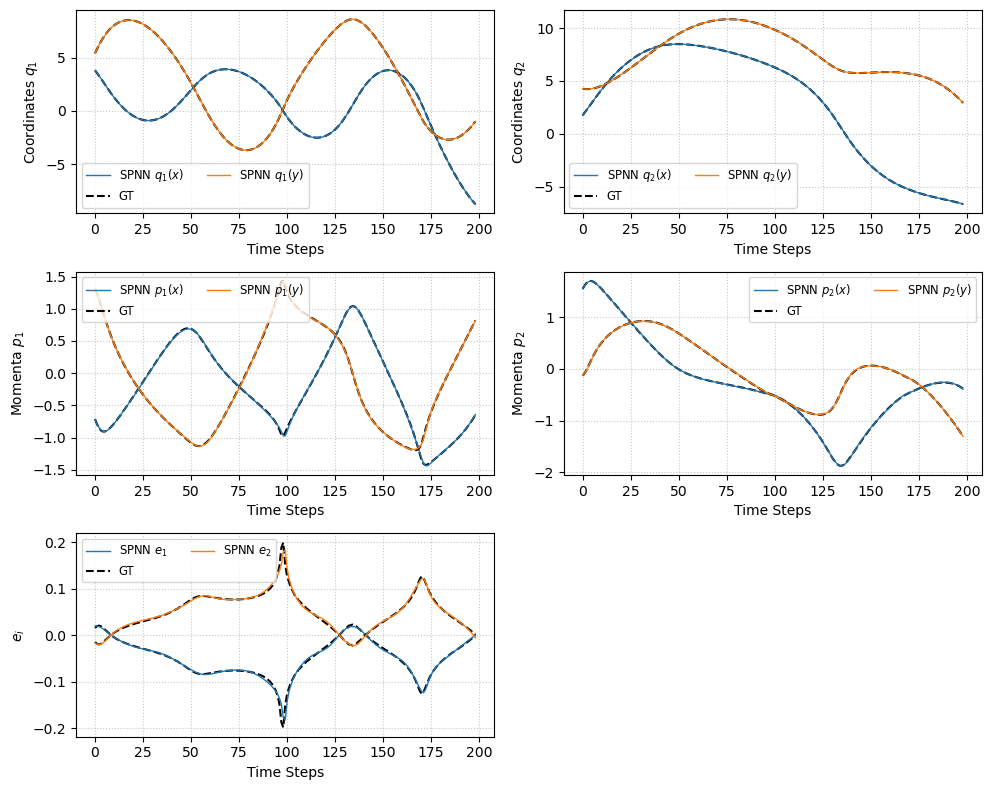

In [7]:
sample_idx = 0
model.eval()

# Using a specific index from our test split
trajectory_data = Z[test_indices[sample_idx]]

# Ground Truth: z(t) for input, z(t+1) for comparison
z_in = trajectory_data[:, :-1].T
z_target = trajectory_data[:, 1:].T

with torch.no_grad():
    z_pred, dE, dS = model(z_in, L, M, dt)

plot_system_grid(z_target, z_pred)